## A/B Testing, Randomized Controlled Trials

- We want to estimate the **average treatment effect**: The average difference in outcomes between the treatment and control groups
- Remember, the stakes are something like: If we implement this intervention at the scale of millions of patients, how many lives are:
    - Saved because the treatment works and our experiment showed it did (Good)
    - Not lost because the treatment doesn't work and our experiment showed it doesn't work (Good)
    - Not saved because the treatment works but our experiment failed to show it did (Bad)
    - Lost because the treatment actually harms patients, but our experiment falsely suggested it works (Very bad)

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

We generally can't compare what would have happened to observation $i$, if they had been assigned to the other treatment. This means we only observe
$$
y_{iA} = \text{Outcome for $i$ receiving treatment $A$ }
$$
or
$$
y_{iB} = \text{Outcome for $i$ receiving treatment $B$ }
$$
but not both. The **average outcome** for group $A$ is
$$
\frac{1}{\text{Size of group } A} \sum_{i \text{ receiving } A} y_{iA}
$$
and the **average outcome** for group $B$ is
$$
\frac{1}{\text{Size of group } B} \sum_{i \text{ receiving } B} y_{iB}.
$$
When we difference them, we get the **Average Treatment Effect (ATE)**:
$$
ATE = \dfrac{1}{\text{Size of group } A} \sum_{i \text{ receiving } A} y_{iA} \quad - \quad \frac{1}{\text{Size of group } B} \sum_{i \text{ receiving } B} y_{iB}
$$
As long as treatment is randomly assigned, there is no reason to think that the participants in group $A$ or $B$ are systematically different, and the **ATE** is an unbiased estimator of the true contrast in outcomes between groups $B$ and $A$. We "average away" the differences across the two groups to get an estimate of the difference in outcomes.

We then use bootstrapping to do two things:

1. Estimate the density/distribution for the averages outcomes in both groups
2. Estimate the ATE and its density/distribution

## Part 1

- First, we're going to evaluate a particular clinical trial, on chronic kidney disease:
    - ISCHEMIA-Chronic Kidney Disease Trial (ISCHEMIA-CKD)
    - ClinicalTrials.gov ID NCT01985360
    - Sponsor NYU Langone Health
    - Information provided by NYU Langone Health (Responsible Party)
- The study compared a "routine invasive therapy" (intra-aortic balloon pumps) intended to reduce death/heart attack versus more conservative medical interventions during heart surgery

<div>
<img src="./src/ischemia.png" width="700"/>
</div>

**1.** Load the `./data/iabp.csv` data. Cross tabulate `Group` and `Survived`. What is the point estimate of the ATE? Would you rather get the intra aortic balloon pump or not? Remember, **Invasive** means pump and **Conservative** means not.

In [3]:
df = pd.read_csv('./data/iabp.csv')

## Crosstabs, average treatment effect:
print(pd.crosstab( df['Group'], df['Survived']), '\n')

ate = df.loc[ df['Group'] == 'Invasive', 'Survived'].mean() \
    - df.loc[ df['Group'] == 'Conservative', 'Survived'].mean() 
print('Estimated ATE: ', np.round(ate, 3))

Survived      0.0  1.0
Group                 
Conservative  291   98
Invasive      294   94 

Estimated ATE:  -0.01


1. The point estimate/ATE is -0.01, which means about -1 percentage point.  
2. We shouldn't really recommend one solution before the other as we only see a difference between the two groups of about -1 percentage point. However, if we do consider that -1 percentage point significant because of some direction given to us by leadership, we should not recommend the intra aortic balloon pump as we still do see a negative difference found in the point estimate/ATE.

**2.** Bootstrap the average outcome for group A, the average outcome for group B, and difference then to get the ATE, 10,000 times. Store all of these estimates. This is important: **Bootstrap the two groups separately, since this is a clinical trial and there was random assignment (we want to maintain the balance across treatment arms because that maximizes statistical power)**.

In [4]:
## Bootstrapping:
R = 10_000

df_a = df.loc[ df['Group'] == 'Invasive',:]
df_b = df.loc[ df['Group'] == 'Conservative',:]

outcome_a = []
outcome_b = []
ate = [] # Store computed effects

for t in range(R):
    ## Resample:
    df_at = df_a.sample(frac=1.0, replace=True)
    df_bt = df_b.sample(frac=1.0, replace=True)

    ## Evaluate outcomes:
    oat = df_at['Survived'].mean() # Mean outcome for A
    obt = df_bt['Survived'].mean() # Mean outcome for B    

    ## Compute ATE:
    ate_t = oat - obt # Compute ATE for this bootstrap sample
    
    ## Store results:
    outcome_a.append(oat) # Save new value
    outcome_b.append(obt) # Save new value
    ate.append(ate_t) # Save new value

    #len(outcome_a), len(outcome_b), len(ate) -> comparing lengths of bootstrapping lists

**3.** Make a plot of the KDEs of the outcomes for the two groups, and a plot of the ECDFs for the two groups. What relationships do you see between the two groups?

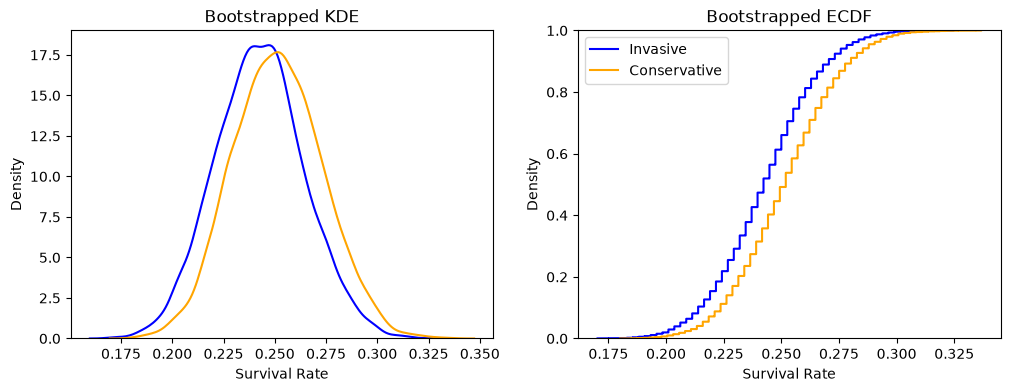

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.kdeplot(outcome_a, label='Invasive', color='blue', ax=ax[0])
sns.kdeplot(outcome_b, label='Conservative', color='orange', ax=ax[0]).set(title='Bootstrapped KDE', xlabel='Survival Rate', ylabel='Density')

sns.ecdfplot(outcome_a, label='Invasive', color='blue', ax=ax[1])
sns.ecdfplot(outcome_b, label='Conservative', color='orange', ax=ax[1]).set(title='Bootstrapped ECDF', xlabel='Survival Rate', ylabel='Density')

plt.legend()
plt.show()

I noticed that the invasive group's ECDF and KDE are slighly shifted to the left of the conservative group. This would mean that the average survival rate of the invasive group is slightly less than the conservative group. This lines up with the ATE value we found earlier with the slight negative value as the difference between the two groups. Further, we also notice that 95% of the values for survival rate lie between around the same range of about 0.20 to 0.29. 

Also, on the ECDF, we can note that the conservative group shows bootstrap mean values in the slightly higher survival rates than we notice in the invasive group. The invasive group reaches the value of 1 earlier than the conservative group does. 

However, I feel it is important to note than the two distributions still really overlap mostly. This can probably mean that the difference between the two procedures is not that large or perhaps not even statistically significant. 

**4.** Make a plot of the KDE and ECDF for the ATE. Does it have a roughly bell shape? What range of values are possible for this intervention?

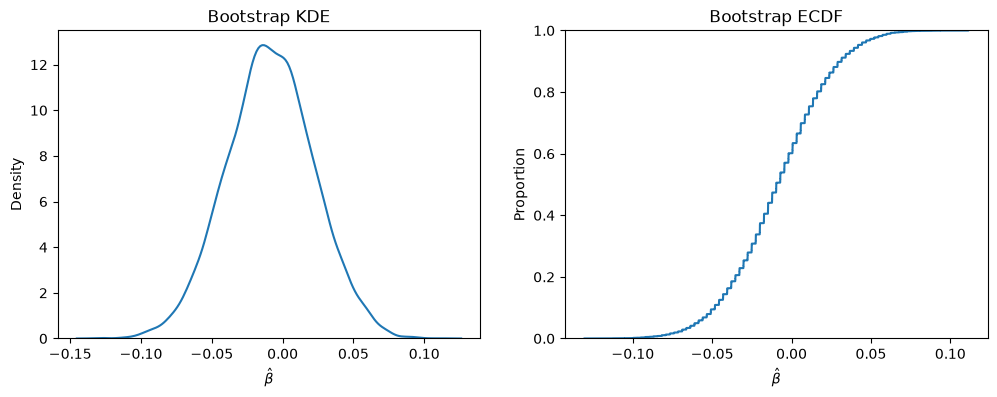

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

## KDE
sns.kdeplot(ate, ax=ax[0])
ax[0].set_xlabel(r"$\hat{\beta}$")
ax[0].set_title("Bootstrap KDE")

## ECDF
sns.ecdfplot(ate, ax=ax[1])
ax[1].set_xlabel(r"$\hat{\beta}$")
ax[1].set_title("Bootstrap ECDF")

plt.show()


Yes, we notice that the KDE is showing a bell shape. This is because we know the averages of many random draws result into a bell shape. 

We notice the range includes both positive and negative numbers throughout all of our boostraps of the ATE. It seems like that we can find the ATE value between -0.10 to 0.10. This includes both positive and negative numbers. It shows that the pump could possibly help or even hurt a bit. However, it is important to note that 0 is in this range so this could mean that there could also be no difference between the invasive and conservative group. 

**5.** Compute 90%, 95%, and 99% confidence intervals for the ATE. Is zero in those intervals? For which do we "fail to reject the null hypothesis that the effect size is zero" and for which do we "reject the null hypothesis that the effect size is zero"?

In [7]:
ci90 = np.quantile(ate, [.05, .95])
ci95 = np.quantile(ate, [.025, .975])
ci99 = np.quantile(ate, [.005, .995])

print(f"90% CI: {ci90}")
print(f"95% CI: {ci95}")
print(f"99% CI: {ci99}")

90% CI: [-0.05864263  0.04184666]
95% CI: [-0.06885882  0.05212281]
99% CI: [-0.08949063  0.07011111]


Yes, zero is in each of the intervals - 90%, 95%, and 99% so we fail to reject the null hypothesis for all the intervals. If zero is inside the confidence interval, we fail to reject the null hypothesis. To be specific, we know that the null hypothesis is telling us that nothing really is happening in our data other than random chance. We fail to reject the null hypothesis, so this means that we cannot rule out that there is no effect between the inputs and the outputs. We can't really find an underlying relationship between the inputs and outputs. So, we can say that we fail to reject the null hypothesis for all intervals calculated. There is no confidence interval or level where we reject the null hypothesis since there is a zero in each of our intervals. 

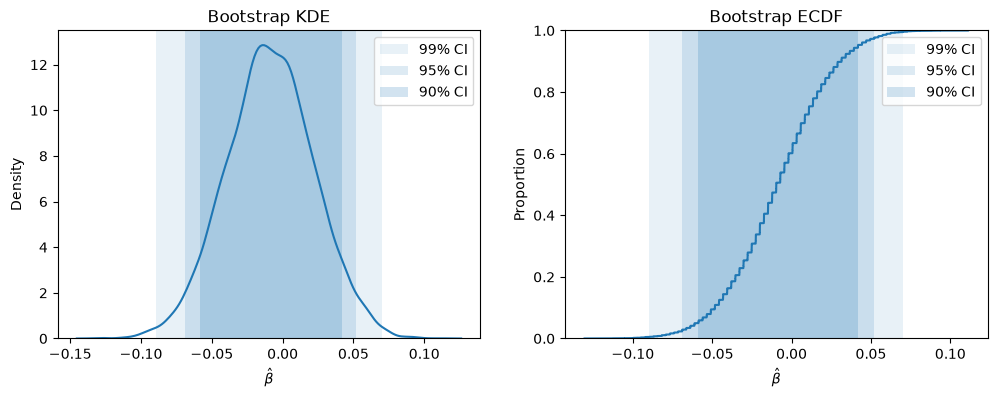

In [8]:
# Percentile bootstrap confidence intervals
ci90 = np.quantile(ate, [.05, .95])
ci95 = np.quantile(ate, [.025, .975])
ci99 = np.quantile(ate, [.005, .995])

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

## KDE
sns.kdeplot(ate, ax=ax[0])

ax[0].axvspan(ci99[0], ci99[1], alpha=0.10, label="99% CI")
ax[0].axvspan(ci95[0], ci95[1], alpha=0.15, label="95% CI")
ax[0].axvspan(ci90[0], ci90[1], alpha=0.20, label="90% CI")

ax[0].set_xlabel(r"$\hat{\beta}$")
ax[0].set_title("Bootstrap KDE")
ax[0].legend()

## ECDF
sns.ecdfplot(ate, ax=ax[1])

ax[1].axvspan(ci99[0], ci99[1], alpha=0.10, label="99% CI")
ax[1].axvspan(ci95[0], ci95[1], alpha=0.15, label="95% CI")
ax[1].axvspan(ci90[0], ci90[1], alpha=0.20, label="90% CI")

ax[1].set_xlabel(r"$\hat{\beta}$")
ax[1].set_title("Bootstrap ECDF")
ax[1].legend()

**6.** What have we learned about inserting balloons into hearts?

We have learned that inserting balloons into hearts does not really support adopting the invasive balloon pump procedure. We notice that there was a slight difference between the ATE on the survival rate of about -0.01. We also noticed that the confidence intervals all include zero, so we also fail to reject the hypothesis that the pump will have no effect on survival. In total, we can say that the trial gives us no evidence that the balloon will help the survival. This does not mean that there can be no effect. We still notice that values are possible between -0.07 and 0.05 in the 95% confidence interval. This shows positive and negative values so it can work, but it also can be a bit harmful. The pump is invasive, so having no evidence to definitively support routine use is a problem. The evidence does not support that we can use this procedure routinely in practice.  

# Part 2

In `./data/diabetes.csv`, there is data from a clinical trial considering three treatments for pre-diabetics to reduce the progression to full diabetes: metformin, rosiglitazone, and lifestyle adjustments (diet, exercise). Unlike Part 1, there aren't two treatment arms (i.e. A = aortic balloon, B = no aortic balloon), but three (met, rosi, lifestyle).

You are a data analyst working for `clinicaltrials.gov` and the FDA to provide an unbiased review of the trial's results. The researchers have provided you with `./data/diabests.csv`.

In an ipynb or py file:

1. Load the `./data/diabetes.csv` data. Cross tabulate the outcomes for the three groups. What are the average outcomes for the three groups? 
2. Bootstrap the outcomes for the three groups 10,000 times. Store all of these estimates. As this is another randomized controlled trial, do the resampling within the arms. 
3. Plot the three densities on one plot and three distributions on another. Describe any patterns you see.
4. There are three treatment effects: met versus rosi, met versus lifestyle, rosi versus lifestyle. Make KDE and ECDF plots of all these comparisons.
5. Compute confidence intervals for each pairwise ATE based on its ECDF (percentile bootstrap). Do you find any statistically significant differences between the interventions? Which seems the most effective?

Then:

6. Write a short report (3-5 paragraphs) that summarizes the evidence from the trial for adopting each of the interventions or not. Use tables and visualizations. Write in a professional tone for a technical audience, and focus on evidence (or the lack thereof). Do not assume anyone has read your work in your notebooks.

Load the `./data/diabetes.csv` data. Cross tabulate the outcomes for the three groups. What are the average outcomes for the three groups? 

In [9]:
df2 = pd.read_csv('./data/diabetes.csv').drop('Unnamed: 0',axis=1)
df2.head()

,treatment,outcome
0,met,success
1,rosi,failure
2,rosi,success
3,lifestyle,success
4,met,success


In [10]:
df2.treatment.unique()

<StringArray>
['met', 'rosi', 'lifestyle']
Length: 3, dtype: str

In [11]:
df2['outcome'] = df2['outcome'].map({'success':1, 'failure':0})
df2.head()

,treatment,outcome
0,met,1
1,rosi,0
2,rosi,1
3,lifestyle,1
4,met,1


In [12]:
pd.crosstab( df2['treatment'], df2['outcome'],margins=True)

outcome,0,1,All
treatment,,,
lifestyle,109,125,234
met,120,112,232
rosi,90,143,233
All,319,380,699


In [13]:
print(df2.groupby('treatment')['outcome'].mean())

treatment
lifestyle    0.534188
met          0.482759
rosi         0.613734
Name: outcome, dtype: float64


The average outcomes for the three groups are:
1. lifestyle = 0.534188
2. met = 0.482759
3. rosi = 0.613734

Bootstrap the outcomes for the three groups 10,000 times. Store all of these estimates. As this is another randomized controlled trial, do the resampling within the arms. 

In [14]:
## Bootstrapping:
R = 10_000

df2_l = df2.loc[ df2['treatment'] == 'lifestyle',:]
df2_m = df2.loc[ df2['treatment'] == 'met',:]
df2_r = df2.loc[ df2['treatment'] == 'rosi',:]

outcome_l = []
outcome_m = []
outcome_r = []


# ate = [] # Store computed effects

for t in range(R):
    #df_t = df.sample( df.shape[0], axis=0, replace=True) # Resample

    df2_lt = df2_l.sample(frac=1.0, replace=True)
    df2_mt = df2_m.sample(frac=1.0, replace=True)
    df2_rt = df2_r.sample(frac=1.0, replace=True)

    olt = df2_lt['outcome'].mean() # Mean outcome for l
    omt = df2_mt['outcome'].mean() # Mean outcome for m
    ort = df2_rt['outcome'].mean() # Mean outcome for r
    # ate_t = oat - obt # Compute ATE for this bootstrap sample

    outcome_l.append(olt) # Save new value
    outcome_m.append(omt) # Save new value
    outcome_r.append(ort) # Save new value
    # ate.append(ate_t) # Save new value

In [15]:
len(outcome_l),len(outcome_m),len(outcome_r)

(10000, 10000, 10000)

Plot the three densities on one plot and three distributions on another. Describe any patterns you see.

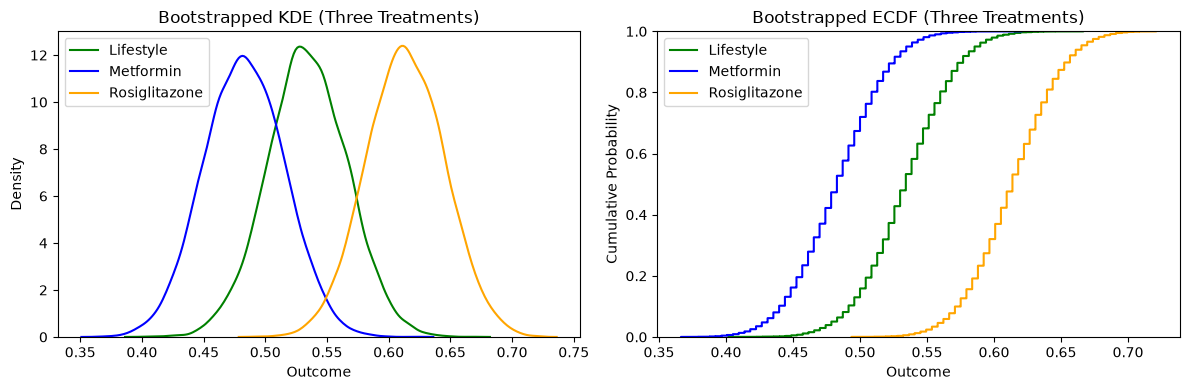

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

## Overlaid KDEs
sns.kdeplot(outcome_l, label='Lifestyle', color='green',  ax=ax[0])
sns.kdeplot(outcome_m, label='Metformin', color='blue',   ax=ax[0])
sns.kdeplot(outcome_r, label='Rosiglitazone', color='orange', ax=ax[0])
ax[0].set(title='Bootstrapped KDE (Three Treatments)',
          xlabel='Outcome', ylabel='Density')
ax[0].legend()

## Overlaid ECDFs
sns.ecdfplot(outcome_l, label='Lifestyle', color='green',  ax=ax[1])
sns.ecdfplot(outcome_m, label='Metformin', color='blue',   ax=ax[1])
sns.ecdfplot(outcome_r, label='Rosiglitazone', color='orange', ax=ax[1])
ax[1].set(title='Bootstrapped ECDF (Three Treatments)',
          xlabel='Outcome', ylabel='Cumulative Probability')
ax[1].legend()

plt.tight_layout()
plt.show()

We notice that Metformin is farthest left compared to the other two treatments. Lifestyle changes is in the middle between the two treatments and Rosiglitazone is furthest right. We also notice that Metformin and Rosiglitazone barely overlap, showing that there is a larger difference between these two groups. Also, on the ECDF plot, we notice that the Rosiglitazone curve sits to the right of the other plots. This means that the success rates are higher compared to the other treatments. Metformin is the further to the left on the ECDF too and the lifestyle changes lie in the middle for the ECDF plot as well. 

There are three treatment effects: met versus rosi, met versus lifestyle, rosi versus lifestyle. Make KDE and ECDF plots of all these comparisons.

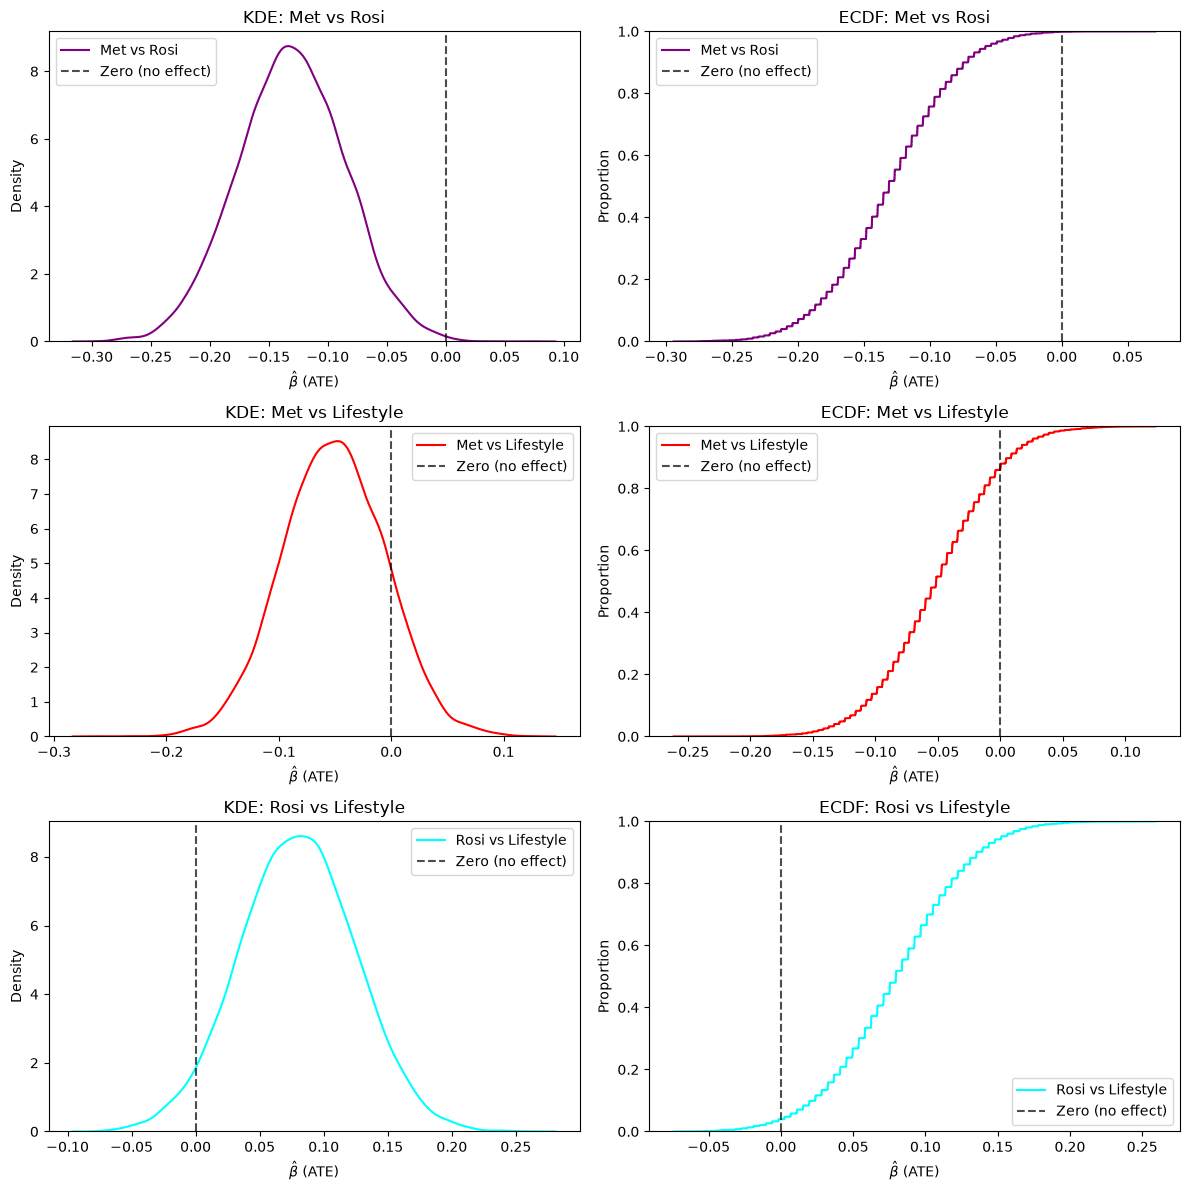

In [17]:
## Compute pairwise ATEs for each bootstrap sample
ate_mr = np.array(outcome_m) - np.array(outcome_r)  # met vs rosi
ate_ml = np.array(outcome_m) - np.array(outcome_l)  # met vs lifestyle
ate_rl = np.array(outcome_r) - np.array(outcome_l)  # rosi vs lifestyle

fig, ax = plt.subplots(3, 2, figsize=(12, 12))

comparisons = [
    (ate_mr, 'Met vs Rosi',        'purple'),
    (ate_ml, 'Met vs Lifestyle',   'red'),
    (ate_rl, 'Rosi vs Lifestyle',  'cyan'),
]

for i, (ate_vals, label, color) in enumerate(comparisons):
    ## KDE (left column)
    sns.kdeplot(ate_vals, ax=ax[i, 0], color=color, label=label)
    ax[i, 0].axvline(0, color='k', linestyle='--', alpha=0.7, label='Zero (no effect)')
    ax[i, 0].set_title(f'KDE: {label}')
    ax[i, 0].set_xlabel(r'$\hat{\beta}$ (ATE)')
    ax[i, 0].legend()

    ## ECDF (right column)
    sns.ecdfplot(ate_vals, ax=ax[i, 1], color=color, label=label)
    ax[i, 1].axvline(0, color='k', linestyle='--', alpha=0.7, label='Zero (no effect)')
    ax[i, 1].set_title(f'ECDF: {label}')
    ax[i, 1].set_xlabel(r'$\hat{\beta}$ (ATE)')
    ax[i, 1].legend()

plt.tight_layout()
plt.show()

Compute confidence intervals for each pairwise ATE based on its ECDF (percentile bootstrap). Do you find any statistically significant differences between the interventions? Which seems the most effective?

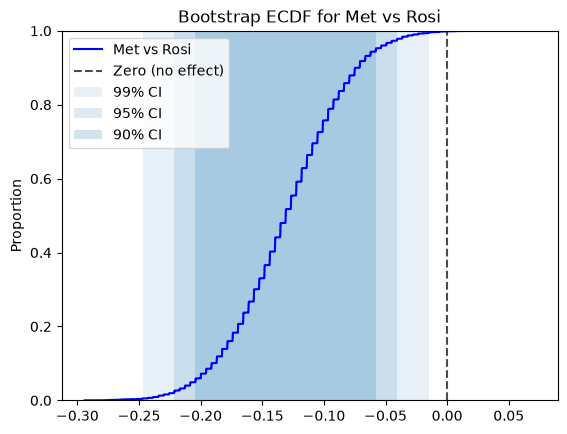

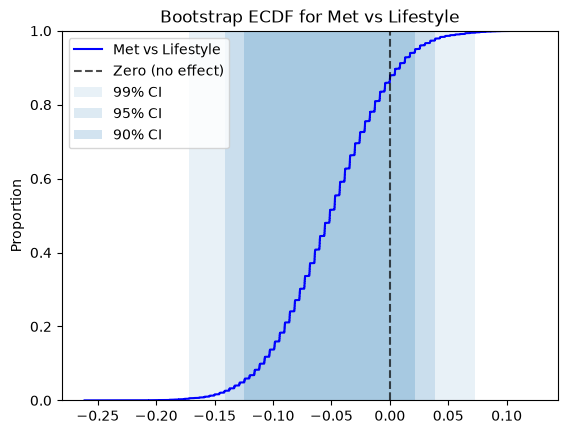

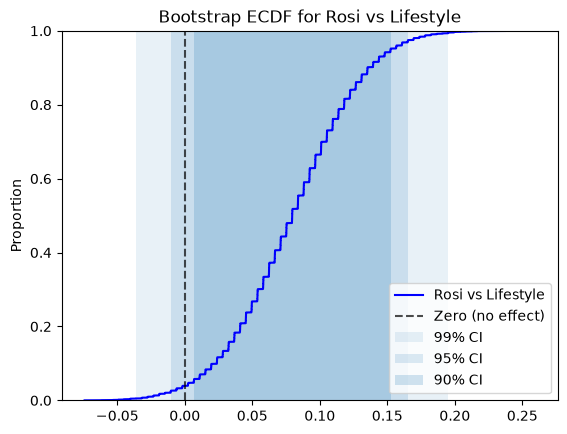

       Comparison Level    ATE  CI low  CI high  Zero inside?
      Met vs Rosi   90% -0.131  -0.204   -0.058         False
      Met vs Rosi   95% -0.131  -0.221   -0.041         False
      Met vs Rosi   99% -0.131  -0.247   -0.015         False
 Met vs Lifestyle   90% -0.051  -0.125    0.022          True
 Met vs Lifestyle   95% -0.051  -0.141    0.039          True
 Met vs Lifestyle   99% -0.051  -0.172    0.073          True
Rosi vs Lifestyle   90%  0.080   0.007    0.152         False
Rosi vs Lifestyle   95%  0.080  -0.010    0.165          True
Rosi vs Lifestyle   99%  0.080  -0.036    0.195          True


'       Comparison Level    ATE  CI low  CI high  Zero inside?\n      Met vs Rosi   90% -0.131  -0.204   -0.058         False\n      Met vs Rosi   95% -0.131  -0.221   -0.041         False\n      Met vs Rosi   99% -0.131  -0.247   -0.015         False\n Met vs Lifestyle   90% -0.051  -0.125    0.022          True\n Met vs Lifestyle   95% -0.051  -0.141    0.039          True\n Met vs Lifestyle   99% -0.051  -0.172    0.073          True\nRosi vs Lifestyle   90%  0.080   0.007    0.152         False\nRosi vs Lifestyle   95%  0.080  -0.010    0.165          True\nRosi vs Lifestyle   99%  0.080  -0.036    0.195          True'

In [ ]:
ates = [ate_mr, ate_ml, ate_rl]
names = ['Met vs Rosi', 'Met vs Lifestyle', 'Rosi vs Lifestyle']

rows = []   # must be created BEFORE the loop

for ate, name in zip(ates, names):
    ci90 = np.quantile(ate, [.05, .95])
    ci95 = np.quantile(ate, [.025, .975])
    ci99 = np.quantile(ate, [.005, .995])

    sns.ecdfplot(ate, label=name, color='blue')
    plt.axvline(0, color='k', linestyle='--', alpha=0.7, label='Zero (no effect)')
    plt.axvspan(ci99[0], ci99[1], alpha=0.10, label="99% CI")
    plt.axvspan(ci95[0], ci95[1], alpha=0.15, label="95% CI")
    plt.axvspan(ci90[0], ci90[1], alpha=0.20, label="90% CI")
    plt.title(f"Bootstrap ECDF for {name}")
    plt.legend()
    plt.show()

    for level, ci in [('90%', ci90), ('95%', ci95), ('99%', ci99)]:
        rows.append({'Comparison': name,
                     'Level': level,
                     'ATE': round(ate.mean(), 3),
                     'CI low': round(ci[0], 3),
                     'CI high': round(ci[1], 3),
                     'Zero inside?': ci[0] <= 0 <= ci[1]})

print(pd.DataFrame(rows).to_string(index=False))


We notice that Met vs Rosi is statistically significant as zero is outside all of our confidence intervals. Met vs. Lifestyle has zero inside all three confidence interval levels, so we know that this is not statistically significant. Rosi vs Lifestyle show zero is outside the 90% confidence interval but zero is inside the 95% and 99% confidence interval. 

As Met vs Rosi is statistically significant, we can say that Metformin does worse than Rosiglitazone. 

Further, we can say that Rosiglitazone seems to be the most effective because the confidence interval with Met vs Rosi is significant and shows that Rosi is better than the effectiveness of the Met drug. We notice that at 90%, Rosi vs Lifestyle is significant and so we can say that Rosi does lead in effectiveness with this treatment as well.

I used Claude and ChatGPT in order to generate code and understand concepts with this lab.